In [1]:
using LinearAlgebra
using PyPlot
using Trapz
using Calculus

In [39]:
function H_Guo_dna(
        onsight_c1::Array{Array},
        onsight_c2::Array{Array},
        thopping::Array{Float64}, 
        lambda::Array{Float64},
        )
    N = length(onsight_c1[1])* 4
    onsight_e = [onsight_c1; onsight_c2]
    
    Mtrx = zeros(Float64, N,N)
    for i in 1:4:N # i = number of site n bloc
        i_steps = Integer((i+3)/4)
        Mtrx[i+2, i] = lambda[i_steps] 
        Mtrx[i, i+2] = lambda[i_steps]
        Mtrx[i+3, i+ 1] = lambda[i_steps] 
        Mtrx[i+ 1, i+3] = lambda[i_steps]
        
        for j in 1:1:4 # j = indexing  inside the bloc
        
        #diagonaleinträge
        Mtrx[(i+ j -1), (i+ j - 1)] = onsight_e[j][i_steps]
        
            if i<N-4
                #rechte hopping matrix
                Mtrx[(i +3 +j), (j +i-1)] = thopping[j]  
                #untere hoping matrix
                Mtrx[(j +i -1), (i+3 + j)] = thopping[j]
            end   
        end
    end
    return Matrix(Mtrx)
end 

function H_Guo_so(
        onsight_c1::Array{Array},
        onsight_c2::Array{Array},
        sigma::Array{Float64},
        )
    N = length(onsight_c1[1])* 4
    
    Mtrx = zeros(Float64, N,N)
    for i in 1:4:N # i = number of site n bloc
        i_steps = Integer((i+3)/4)
       
        if i<N-4
            for z in 0:2:2
            #rechte hopping matrix
            Mtrx[(i +z), (i+5 +z)] = sigma[1 + z]
            Mtrx[(i +z+1), (i+4 +z)] = sigma[2+z]
            #untere hoping matrix
            Mtrx[(i +5 +z), (i +z)] = sigma[1+z] 
            Mtrx[(i +4 +z), (i +1 +z)] = sigma[2+z] 
            end
        end   

    
    end
    return Matrix(Mtrx)
end 

H_Guo_so (generic function with 1 method)

[3.0 3.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 3.0 3.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0]

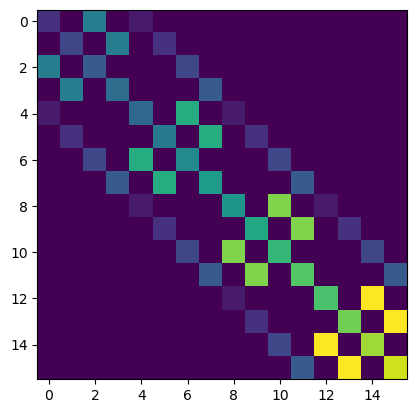

PyObject <matplotlib.image.AxesImage object at 0x7f3018045100>

In [43]:
#just some tests with adressing bloc matrices
matri = zeros(Float64, 10, 10) 
matri[1:2, 1:2] .= 3
show( Matrix(matri))

# def of onsight energies
n = 4 # number of sites
onsight_chain1 = Array[[range(0.2, 1., length =n )]; [range(0.3, 1.1, length = n)]] # spin up; spin down
onsight_chain2 = Array[[range(0.4, 1.2, length = n)]; [range(.5, 1.3, length = n)]]
t_hopping= Array([0.1 0.2 0.3 0.4])
#same length as n sites = length of bsp. up c1 energies
lambda = Array(range(0.6, 1.4, length = n))


H = H_Guo_dna(onsight_chain1, onsight_chain2, t_hopping, lambda)
plt.imshow(H)



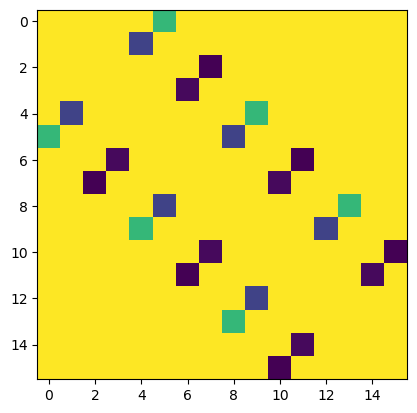

PyObject <matplotlib.image.AxesImage object at 0x7f3017c85430>

In [55]:
sigma = [-.5 -1.2 -1.5 -1.46]
Hso = H_Guo_so(onsight_chain1, onsight_chain2,sigma)
plt.imshow(Hso)

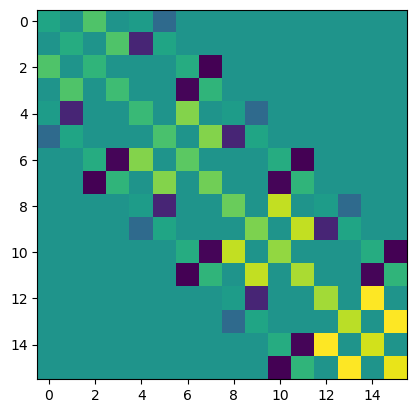

PyObject <matplotlib.image.AxesImage object at 0x7f3017be0a30>

In [56]:
plt.imshow(Hso + H)